# Customer and Returns Analysis

## Purpose

In this notebook, I explore how customers buy, how much profit they generate, and what drives order returns, building directly on the cleaned Superstore dataset from Notebook 1.

## Main Objectives

1. Structure the data into clear customer-level and order-level tables for analysis.
2. See how one-time buyers stack up against repeat customers.
3. Pinpoint the most profitable customers alongside those who are costing the business money.
4. Understand how heavily the overall profits rely on top customers.
5. Group customers into meaningful segments based on how recently, frequently, and heavily they shop.
6. Measure true return rates based on unique orders rather than individual product lines.
7. Compare returned orders against successful ones to spot patterns in performance.
8. Wrap up with clean summary tables, visuals, and practical recommendations for the business.

In [1]:
from pathlib import Path

# Importing pandas for loading and analysing tabular data.
import numpy as np

# Import NumPy for numerical checks such as np.isclose().
import pandas as pd


# To find the directory from which the notebook is running.

CURRENT_DIR = Path.cwd()


# If the notebook is running from the notebooks folder, move one level upward to locate the main project folder.

if CURRENT_DIR.name == "notebooks":
    PROJECT_ROOT = CURRENT_DIR.parent
else:
    PROJECT_ROOT = CURRENT_DIR


# Define input and output folder locations.

RAW_DATA_DIR = PROJECT_ROOT / "data" / "raw"

PROCESSED_DATA_DIR = (
    PROJECT_ROOT / "data" / "processed"
)

TABLES_DIR = (
    PROJECT_ROOT / "results" / "tables"
)

FIGURES_DIR = (
    PROJECT_ROOT / "results" / "figures"
)


# Create the output folders.


for folder in [
    PROCESSED_DATA_DIR,
    TABLES_DIR,
    FIGURES_DIR
]:
    folder.mkdir(
        parents=True,
        exist_ok=True
    )


In [2]:
# Confirming that the folders needed by Notebook 3 are available.
folder_check = pd.Series({
    "processed_data": PROCESSED_DATA_DIR.exists(),
    "tables": TABLES_DIR.exists(),
    "figures": FIGURES_DIR.exists()
})

assert folder_check.all()

folder_check

processed_data    True
tables            True
figures           True
dtype: bool

## 1. Data Loading and Validation

In [3]:
# Defining the processed dataset created in Notebook 1.
ORDERS_ENRICHED_FILE = (
    PROCESSED_DATA_DIR / "orders_enriched.csv"
)

# Stop execution immediately if the required file is unavailable.
assert ORDERS_ENRICHED_FILE.exists(), (
    f"Processed dataset not found: {ORDERS_ENRICHED_FILE}"
)

In [4]:
# Loaded reusable processed dataset.
orders_enriched = pd.read_csv(
    ORDERS_ENRICHED_FILE,
    parse_dates=["Order Date", "Ship Date"],
    dtype={"Postal Code": "string"}
)

In [5]:
# Only those columns are fetched that are required for customer and returns analysis.
required_columns = {
    "Row ID",
    "Order ID",
    "Order Date",
    "Customer ID",
    "Customer Name",
    "Segment",
    "Region",
    "Category",
    "Sub-Category",
    "Sales",
    "Profit",
    "Quantity",
    "Returned"
}

# Identify missing columns from the dataset that are required 
missing_columns = required_columns.difference(
    orders_enriched.columns
)

assert not missing_columns, (
    f"Required columns are missing: {missing_columns}"
)

# Validating the previously confirmed processed-data dimensions.
assert orders_enriched.shape == (10194, 23)

assert orders_enriched["Order ID"].notna().all()
assert orders_enriched["Customer ID"].notna().all()

# The return column should contain only the two expected values.
assert orders_enriched["Returned"].isin(["Yes", "No"]).all()

In [6]:
## Displaying the results
loading_summary = pd.Series({
    "Product-line rows": len(orders_enriched),
    "Unique orders": orders_enriched["Order ID"].nunique(),
    "Unique customers": orders_enriched["Customer ID"].nunique(),
    "Returned order IDs": (
        orders_enriched
        .loc[
            orders_enriched["Returned"].eq("Yes"),
            "Order ID"
        ]
        .nunique()
    )
})

loading_summary

Product-line rows     10194
Unique orders          5111
Unique customers        804
Returned order IDs      296
dtype: int64

## 2. Building an Order-Level Table

Because the raw dataset records one row per product item—and a single order often includes multiple items—simply counting rows would artificially inflate our order and return numbers.

To get accurate order and return metrics, the table below rolls the data up so that each unique order is represented by a single row.

In [7]:
order_summary = (
    orders_enriched
    .groupby(
        [
            "Order ID",
            "Order Date",
            "Customer ID",
            "Customer Name",
            "Segment",
            "Region"
        ],
        as_index=False
    )
    .agg(
        Total_Sales=("Sales", "sum"),
        Total_Profit=("Profit", "sum"),
        Total_Quantity=("Quantity", "sum"),

        # Count of how many product-line rows belong to each order.
        Product_Lines=("Row ID", "size"),

        # Categorised the complete order as returned when any of its  product-line rows has the value "Yes".
        Returned=(
            "Returned",
            lambda values: (
                "Yes" if values.eq("Yes").any() else "No"
            )
        )
    )
)

In [8]:
# Created one row per unique order 

order_summary = (
    orders_enriched
    .groupby("Order ID", as_index=False)
    .agg(
        Order_Date=("Order Date", "first"),
        Customer_ID=("Customer ID", "first"),
        Customer_Name=("Customer Name", "first"),
        Segment=("Segment", "first"),
        Region=("Region", "first"),
        Returned=("Returned", "first"),
        Total_Sales=("Sales", "sum"),
        Total_Profit=("Profit", "sum"),
        Total_Quantity=("Quantity", "sum"),
        Product_Lines=("Row ID", "size")
    )
)

In [9]:
assert order_summary.shape == (5111, 11)
assert order_summary["Order ID"].is_unique
assert order_summary["Returned"].eq("Yes").sum() == 296

assert np.isclose(
    order_summary["Total_Sales"].sum(),
    orders_enriched["Sales"].sum()
)

assert np.isclose(
    order_summary["Total_Profit"].sum(),
    orders_enriched["Profit"].sum()
)

assert (
    order_summary["Total_Quantity"].sum()
    == orders_enriched["Quantity"].sum()
)

order_summary.head()

,Order ID,Order_Date,Customer_ID,Customer_Name,Segment,Region,Returned,Total_Sales,Total_Profit,Total_Quantity,Product_Lines
0,CA-2023-100867,2023-10-19,EH-14125,Eugene Hildebrand,Home Office,West,No,32.700,8.5000,3,1
1,CA-2023-107153,2023-09-28,GZ-14545,George Zrebassa,Corporate,East,No,10.688,3.7408,2,1
2,CA-2023-115238,2023-01-21,JW-15220,Jane Waco,Corporate,East,No,281.160,89.2000,22,5
3,CA-2023-115777,2023-08-19,DO-13645,Doug O'Connell,Consumer,East,No,387.990,182.3600,1,1
4,CA-2023-117964,2023-12-02,MK-19560,Michael Knudson,Corporate,East,No,56.424,-18.5354,12,2


## 3. Overall Return Performance

In [10]:
# Calculating the return metrics using unique orders
total_orders = len(order_summary)

returned_orders = (
    order_summary["Returned"]
    .eq("Yes")
    .sum()
)

non_returned_orders = total_orders - returned_orders

return_rate_percent = (
    returned_orders
    / total_orders
    * 100
)

return_kpis = pd.Series({
    "Total Orders": total_orders,
    "Returned Orders": returned_orders,
    "Non-Returned Orders": non_returned_orders,
    "Return Rate (%)": return_rate_percent
}, name="Value")

In [11]:
return_kpis_display = pd.Series({
    "Total Orders": f"{total_orders:,}",
    "Returned Orders": f"{returned_orders:,}",
    "Non-Returned Orders": f"{non_returned_orders:,}",
    "Return Rate": f"{return_rate_percent:.2f}%"
}, name="Value")

return_kpis_display

Total Orders           5,111
Returned Orders          296
Non-Returned Orders    4,815
Return Rate            5.79%
Name: Value, dtype: str

In [12]:
return_status_performance = (
    order_summary
    .groupby("Returned", as_index=False)
    .agg(
        Unique_Orders=("Order ID", "nunique"),
        Total_Sales=("Total_Sales", "sum"),
        Total_Profit=("Total_Profit", "sum"),
        Total_Quantity=("Total_Quantity", "sum"),
        Average_Order_Value=("Total_Sales", "mean"),
        Average_Profit_Per_Order=("Total_Profit", "mean")
    )
)

# Calculating  profit relative to sales for each return.
return_status_performance["Profit_Margin_percent"] = (
    return_status_performance["Total_Profit"]
    / return_status_performance["Total_Sales"]
    * 100
)

In [13]:
## Validating the summary results
assert (
    return_status_performance["Unique_Orders"].sum()
    == len(order_summary)
)

assert np.isclose(
    return_status_performance["Total_Sales"].sum(),
    order_summary["Total_Sales"].sum()
)

assert np.isclose(
    return_status_performance["Total_Profit"].sum(),
    order_summary["Total_Profit"].sum()
)

In [14]:
return_status_performance.style.format({
    "Unique_Orders": "{:,.0f}",
    "Total_Sales": "{:,.0f}",
    "Total_Profit": "{:,.0f}",
    "Total_Quantity": "{:,.0f}",
    "Average_Order_Value": "{:,.2f}",
    "Average_Profit_Per_Order": "{:,.2f}",
    "Profit_Margin_percent": "{:.2f}%"
})

,Returned,Unique_Orders,Total_Sales,Total_Profit,Total_Quantity,Average_Order_Value,Average_Profit_Per_Order,Profit_Margin_percent
0,No,"4,815","2,146,030","269,064","35,601",445.70,55.88,12.54%
1,Yes,296,"180,504","23,232","3,053",609.81,78.49,12.87%


### Initial Return Observations

- Out of 5,111 unique orders, 296 were returned, putting our overall order return rate at roughly 5.79%.
- Orders that ended up being returned actually had a noticeably higher average value (609.81) compared to non-returned orders ($445.70).
- Returned orders also showed a slightly higher recorded profit margin (12.87% vs. 12.54% for non-returned orders).
- **Caution:** These numbers only reflect the original sales and profit logged when the orders were placed. Because the dataset doesn't track refund payouts, return, return dates, or recovered inventory value, we can't calculate the true net financial hit—nor can we assume returned orders were actually more profitable.

## 4. Customer-Level Performance

### Customer Identifier Quality Check

As there there are more unique customer IDs than customer names in the raw dataset, the checks below help us verify whether multiple IDs actually belong to the same person, and ensure no single order is accidentally tied to more than one customer ID.

In [16]:
# Identifying customer names connected to multiple customer IDs.
customer_id_quality = (
    orders_enriched
    .groupby("Customer Name", as_index=False)
    .agg(
        Customer_ID_Count=("Customer ID", "nunique"),

        Customer_IDs=(
            "Customer ID",  lambda values: ", ".join(
                sorted(values.unique())
            )
        ),

        Segment_Count=("Segment", "nunique"),
        Country_Count=("Country/Region", "nunique"),
        City_Count=("City", "nunique"),
        State_Count=("State/Province", "nunique")
    )
)

customer_id_anomalies = customer_id_quality.loc[
    customer_id_quality["Customer_ID_Count"].gt(1)
]

customer_id_anomalies

,Customer Name,Customer_ID_Count,Customer_IDs,Segment_Count,Country_Count,City_Count,State_Count
324,Harry Olson,5,"HO-15230, HO-15231, HO-15232, HO-15233, HO-15234",1,1,1,1


In [17]:
order_customer_id_quality = (
    orders_enriched
    .groupby("Order ID", as_index=False)
    .agg(
        Customer_ID_Count=("Customer ID", "nunique"),
        Customer_Name_Count=("Customer Name", "nunique")
    )
)

order_customer_id_anomalies = (
    order_customer_id_quality
    .loc[
        order_customer_id_quality["Customer_ID_Count"].gt(1)
    ]
)

order_customer_id_anomalies

,Order ID,Customer_ID_Count,Customer_Name_Count
47,CA-2025-121465,4,1
83,CA-2026-130494,4,1


## Conclusion

The raw dataset has inconsistent customer IDs for Harry Olson—even though his name and other details stay the same, his two orders are linked to four different IDs. Because of this, relying on `Customer ID` alone would accidentally split him into multiple people and inflate the customer count.

Instead, after verifying that `Customer Name` maps cleanly and consistently to both segment and location, I've used `Customer Name` as the primary customer key for this analysis, giving us 800 unique customers.

In [18]:
#  To confirm that every customer name belongs to one segment only.
# Geography(State/city/country) is excluded because customers may place orders  from multiple cities, states or countries.
customer_name_consistency = (
    orders_enriched
    .groupby("Customer Name")
    .agg(
        Segment_Values=("Segment", "nunique")
    )
)

assert (
    customer_name_consistency["Segment_Values"]
    .eq(1)
    .all()
)

# Reconfirmed that every order  maps to exactly one customer name.
# This remains true even though two orders contain multiple customer IDs.
order_customer_name_consistency = (
    orders_enriched
    .groupby("Order ID")["Customer Name"]
    .nunique()
)

assert order_customer_name_consistency.eq(1).all()

In [19]:
# Creating a table with one row per customer name from the one-row-per-order table.
customer_performance = (
    order_summary
    .groupby("Customer_Name", as_index=False)
    .agg(
        Segment=("Segment", "first"),
        First_Order=("Order_Date", "min"),
        Last_Order=("Order_Date", "max"),
        Unique_Orders=("Order ID", "nunique"),
        Total_Sales=("Total_Sales", "sum"),
        Total_Profit=("Total_Profit", "sum"),
        Total_Quantity=("Total_Quantity", "sum"),
        Returned_Orders=("Returned", lambda status: status.eq("Yes").sum()),
    )
)

# Adding the labels  to be used in the later customer analyses.
customer_performance["Average_Order_Value"] = (
    customer_performance["Total_Sales"] / customer_performance["Unique_Orders"]
)
customer_performance["Profit_Margin_percent"] = (
    100 * customer_performance["Total_Profit"] / customer_performance["Total_Sales"]
)
customer_performance["Return_Rate_percent"] = (
    100 * customer_performance["Returned_Orders"] / customer_performance["Unique_Orders"]
)
customer_performance["Purchase_Type"] = np.where(
    customer_performance["Unique_Orders"].eq(1), "One-time", "Repeat"
)
customer_performance["Profit_Status"] = np.select(
    [
        customer_performance["Total_Profit"].gt(0),
        customer_performance["Total_Profit"].lt(0),
    ],
    ["Profitable", "Loss-making"],
    default="Break-even",
)

# ReConfirmed that no order was lost when grouping by customer name.
assert customer_performance["Unique_Orders"].sum() == len(order_summary)

print(f"Customer-name groups: {len(customer_performance):,}")
print(customer_performance["Purchase_Type"].value_counts().to_string())

Customer-name groups: 800
Purchase_Type
Repeat      788
One-time     12


## 5. One-Time and Repeat Customer Performance

In [20]:
purchase_type_performance = (
    customer_performance
    .groupby("Purchase_Type", as_index=False)
    .agg(
        Customer_Count=("Customer_Name", "size"),
        Total_Orders=("Unique_Orders", "sum"),
        Total_Sales=("Total_Sales", "sum"),
        Total_Profit=("Total_Profit", "sum"),
        Returned_Orders=("Returned_Orders", "sum"),

        Average_Sales_Per_Customer=("Total_Sales", "mean"),
        Average_Profit_Per_Customer=("Total_Profit", "mean")
    )
)

In [21]:
purchase_type_performance["Orders_Per_Customer"] = (
    purchase_type_performance["Total_Orders"]
    / purchase_type_performance["Customer_Count"]
)

purchase_type_performance["Profit_Margin_percent"] = (
    purchase_type_performance["Total_Profit"]
    / purchase_type_performance["Total_Sales"]
    * 100
)

purchase_type_performance["Return_Rate_percent"] = (
    purchase_type_performance["Returned_Orders"]
    / purchase_type_performance["Total_Orders"]
    * 100
)

In [22]:
assert (
    purchase_type_performance["Customer_Count"].sum()
    == len(customer_performance)
)

assert (
    purchase_type_performance["Total_Orders"].sum()
    == len(order_summary)
)

assert np.isclose(
    purchase_type_performance["Total_Sales"].sum(),
    customer_performance["Total_Sales"].sum()
)

assert np.isclose(
    purchase_type_performance["Total_Profit"].sum(),
    customer_performance["Total_Profit"].sum()
)

assert (
    purchase_type_performance["Returned_Orders"].sum()
    == 296
)

In [23]:
purchase_type_performance.style.format({
    "Customer_Count": "{:,.0f}",
    "Total_Orders": "{:,.0f}",
    "Total_Sales": "{:,.0f}",
    "Total_Profit": "{:,.0f}",
    "Returned_Orders": "{:,.0f}",
    "Average_Sales_Per_Customer": "{:,.2f}",
    "Average_Profit_Per_Customer": "{:,.2f}",
    "Orders_Per_Customer": "{:.2f}",
    "Profit_Margin_percent": "{:.2f}%",
    "Return_Rate_percent": "{:.2f}%"
})

,Purchase_Type,Customer_Count,Total_Orders,Total_Sales,Total_Profit,Returned_Orders,Average_Sales_Per_Customer,Average_Profit_Per_Customer,Orders_Per_Customer,Profit_Margin_percent,Return_Rate_percent
0,One-time,12,12,"5,168",767,1,430.64,63.95,1.00,14.85%,8.33%
1,Repeat,788,"5,099","2,321,367","291,529",295,"2,945.90",369.96,6.47,12.56%,5.79%


## 6. Highest- and Lowest-Profit Customers

In [24]:
customer_profit_columns = [
    "Customer_Name",
    "Segment",
    "Unique_Orders",
    "Total_Sales",
    "Total_Profit",
    "Profit_Margin_percent",
    "Returned_Orders"
]

In [25]:
top_10_profitable_customers = (
    customer_performance
    .nlargest(10, "Total_Profit")
    [customer_profit_columns]
    .reset_index(drop=True)
)

top_10_profitable_customers.style.format({
    "Unique_Orders": "{:,.0f}",
    "Total_Sales": "{:,.0f}",
    "Total_Profit": "{:,.0f}",
    "Profit_Margin_percent": "{:.2f}%",
    "Returned_Orders": "{:,.0f}"
})

,Customer_Name,Segment,Unique_Orders,Total_Sales,Total_Profit,Profit_Margin_percent,Returned_Orders
0,Tamara Chand,Corporate,5,"19,052","8,981",47.14%,1
1,Raymond Buch,Consumer,6,"15,117","6,976",46.15%,1
2,Sanjit Chand,Consumer,9,"14,142","5,757",40.71%,2
3,Hunter Lopez,Consumer,6,"12,873","5,622",43.68%,0
4,Adrian Barton,Consumer,10,"14,474","5,445",37.62%,1
5,Tom Ashbrook,Home Office,4,"14,596","4,704",32.23%,0
6,Christopher Martinez,Consumer,4,"8,954","3,900",43.55%,0
7,Keith Dawkins,Corporate,12,"8,181","3,039",37.14%,0
8,Andy Reiter,Consumer,6,"6,608","2,885",43.65%,1
9,Daniel Raglin,Home Office,8,"8,351","2,869",34.36%,0


In [26]:
top_10_loss_making_customers = (
    customer_performance
    .nsmallest(10, "Total_Profit")
    [customer_profit_columns]
    .reset_index(drop=True)
)

top_10_loss_making_customers.style.format({
    "Unique_Orders": "{:,.0f}",
    "Total_Sales": "{:,.0f}",
    "Total_Profit": "{:,.0f}",
    "Profit_Margin_percent": "{:.2f}%",
    "Returned_Orders": "{:,.0f}"
})

,Customer_Name,Segment,Unique_Orders,Total_Sales,Total_Profit,Profit_Margin_percent,Returned_Orders
0,Cindy Stewart,Consumer,6,"5,690","-6,626",-116.46%,0
1,Grant Thornton,Corporate,3,"9,351","-4,109",-43.94%,0
2,Luke Foster,Consumer,7,"3,931","-3,584",-91.18%,1
3,Sharelle Roach,Home Office,5,"3,233","-3,334",-103.11%,0
4,Henry Goldwyn,Corporate,12,"3,248","-2,798",-86.15%,1
5,Nathan Cano,Consumer,6,"2,219","-2,205",-99.36%,0
6,Sean Braxton,Corporate,7,"8,058","-2,083",-25.85%,0
7,Sean Miller,Home Office,5,"25,043","-1,981",-7.91%,1
8,Christine Phan,Corporate,8,"5,888","-1,850",-31.42%,0
9,Natalie Fritzler,Consumer,7,"8,323","-1,696",-20.38%,0


## 7. Customer Profit Concentration

In [27]:
profitable_customers = (
    customer_performance
    .loc[  customer_performance["Total_Profit"].gt(0)]
    .sort_values(
        "Total_Profit",ascending=False
    )
    .reset_index(drop=True)
)

In [28]:
positive_profit_pool = (
    profitable_customers["Total_Profit"].sum()
)

loss_pool = (
    customer_performance
    .loc[
        customer_performance["Total_Profit"].lt(0),
        "Total_Profit"
    ]
    .sum()
)

# Positive profit plus losses should be equal to net business profit.
assert np.isclose(
    positive_profit_pool + loss_pool,
    customer_performance["Total_Profit"].sum()
)

In [29]:
concentration_rows = []

for customer_share in [0.10, 0.20, 0.25]:


    customer_count = int(
        np.ceil(
            len(profitable_customers)
            * customer_share )
    )

    selected_profit = (
        profitable_customers
        .head(customer_count)["Total_Profit"]
        .sum()
    )

    contribution_percent = (
        selected_profit
        / positive_profit_pool
        * 100
    )

    concentration_rows.append({
        "Customer_Group": (
            f"Top {customer_share:.0%}"
        ),
        "Customer_Count": customer_count,
        "Selected_Profit": selected_profit,
        "Positive_Profit_Contribution_percent": (
        contribution_percent
        )
})

profit_concentration = pd.DataFrame(
    concentration_rows
)

In [30]:
profit_concentration.style.format({
    "Customer_Count": "{:,.0f}",
    "Selected_Profit": "{:,.0f}",
    "Positive_Profit_Contribution_percent": "{:.2f}%"
})

,Customer_Group,Customer_Count,Selected_Profit,Positive_Profit_Contribution_percent
0,Top 10%,65,"148,205",40.73%
1,Top 20%,129,"214,291",58.90%
2,Top 25%,161,"238,072",65.43%


## Important
The denominator is the positive profit pool, not net total profit. Using net profit would inflate the concentration percentage because customer losses will reduce the denominator.

## Conclusion

1. **Purchase behaviour:** Almost all of our customers come back to order again. 789 placed two or more orders during this period, while only 12 placed a single order.

2. **Sales per customer:** Because repeat buyers make up nearly the entire customer base, looking at total sales alone can be misleading. Comparing average sales per customer is much clearer: repeat buyers spent an average of $2,942.16 each, compared to $430.64 for one-time buyers. Since repeat customers averaged 6.46 orders each, their higher overall spend comes from buying more frequently rather than spending significantly more per order.

3. **Highest total profit:** Tamara Chand was the most profitable customer, bringing in roughly $8,981 in recorded profit across five orders.

4. **Largest total loss:** On the other hand, Cindy Stewart recorded the largest customer-level loss at $6,626.39 across six orders.

5. **Profit concentration:** Our top 65 most profitable customers (roughly the top 10% of profitable buyers) generated 40.73% of all positive customer profit. Keep in mind that this share is calculated before subtracting losses from unprofitable customers, so it reflects gross positive profit rather than overall net profit.

## 8. Order Return Rates by Region and Segment

In [31]:
assert order_summary["Order ID"].is_unique, "Use one row per Order ID."

def summarize_returns(orders, group_column):
    # Count all orders and orders marked as returned within each group.
    summary = (
        orders.groupby(group_column, as_index=False)
        .agg(
            Total_Orders=("Order ID", "size"),
            Returned_Orders=("Returned", lambda status: status.eq("Yes").sum()),
        )
    )

    # Denominator is each group's own order count, not the overall order count.
    summary["Return_Rate_percent"] = (
        100 * summary["Returned_Orders"] / summary["Total_Orders"]
    )

    return (
        summary
        .sort_values("Return_Rate_percent", ascending=False)
        .reset_index(drop=True)
    )

returns_by_region = summarize_returns(order_summary, "Region")

In [32]:
# Created the table  returns_segment using the grouped by Segment.
returns_by_segment = summarize_returns(order_summary, "Segment")


for table in (returns_by_region, returns_by_segment):
    assert table["Total_Orders"].sum() == len(order_summary)
    assert table["Returned_Orders"].sum() == order_summary["Returned"].eq("Yes").sum()

In [33]:
from IPython.display import display

return_rate_format = {"Return_Rate_percent": "{:.2f}%"}

print("Order return rates by region")
display(returns_by_region.style.format(return_rate_format))

print("Order return rates by customer segment")
display(returns_by_segment.style.format(return_rate_format))

Order return rates by region


,Region,Total_Orders,Returned_Orders,Return_Rate_percent
0,West,1635,189,11.56%
1,Central,1179,39,3.31%
2,East,1475,44,2.98%
3,South,822,24,2.92%


Order return rates by customer segment


,Segment,Total_Orders,Returned_Orders,Return_Rate_percent
0,Corporate,1552,93,5.99%
1,Consumer,2628,154,5.86%
2,Home Office,931,49,5.26%


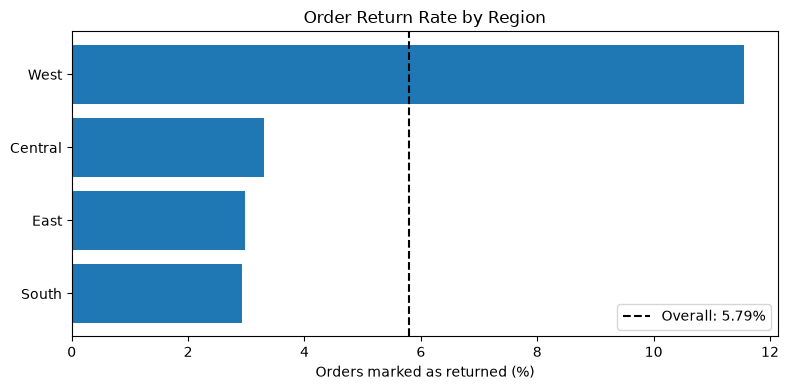

In [34]:
import matplotlib.pyplot as plt

# Calculate the overall rate from order counts, not from an average of regional rates.
overall_return_rate = 100 * order_summary["Returned"].eq("Yes").mean()
region_plot = returns_by_region.sort_values("Return_Rate_percent")

fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(region_plot["Region"], region_plot["Return_Rate_percent"])
ax.axvline(
    overall_return_rate, color="black", linestyle="--",
    label=f"Overall: {overall_return_rate:.2f}%"
)
ax.set_title("Order Return Rate by Region")
ax.set_xlabel("Orders marked as returned (%)")
ax.legend()
fig.tight_layout()

fig.savefig(FIGURES_DIR / "notebook_03_return_rates_by_region.png",
            dpi=300, bbox_inches="tight")
plt.show()

## Explaination
This analysis compares order return rates across regions and customer segments using a deduplicated table (one row per unique order) so multi-item orders aren't double-counted.

While raw counts show volume, **return rates** (`returned orders ÷ total orders`) provide a fairer comparison across groups of different sizes. For instance, although the Consumer segment had more returned orders than Corporate (154 vs. 93), Corporate actually had a slightly higher return rate (5.99% vs. 5.86%).

Both views reconcile to the same 5,111 total orders and 296 returns, though note that the return flag only tracks order-level returns—not specific returned items or refund amounts.

## 9.RFM Customer Segmentation

In [35]:
# Summarize each customer's activity: when they last bought, how often they order, and how much they spend.
snapshot_date = order_summary["Order_Date"].max()

rfm = (
    order_summary.groupby("Customer_Name", as_index=False)
    .agg(
        Last_Order=("Order_Date", "max"),
        Frequency=("Order ID", "nunique"),
        Monetary_value=("Total_Sales", "sum"),
    )
)

# Calculate how many days have passed since each customer's most recent purchase.
rfm["Recency_Days"] = (snapshot_date - rfm["Last_Order"]).dt.days

assert rfm["Frequency"].sum() == len(order_summary)
assert np.isclose(rfm["Monetary_value"].sum(), order_summary["Total_Sales"].sum())
assert rfm["Recency_Days"].ge(0).all()

rfm.head()

,Customer_Name,Last_Order,Frequency,Monetary_value,Recency_Days
0,Aaron Bergman,2025-11-10,3,886.156,415
1,Aaron Hawkins,2026-12-18,7,1744.700,12
2,Aaron Smayling,2026-10-03,7,3050.692,88
3,Adam Bellavance,2026-11-06,8,7755.620,54
4,Adam Hart,2026-11-26,10,3250.337,34


## Definition of RFM metric:
* **Recency (`Recency_Days`):** Tracks how many days have passed since a customer's most recent order—a value of `0` means they placed an order on the very last day recorded in the dataset.
* **Frequency (`Frequency`):** Counts how many unique orders a customer has placed in total.
* **Monetary (`Monetary`):** Reflects total gross sales recorded for that customer, without subtracting refunds or =including in profit.

In [36]:
rfm["R_Score"] = rfm["Recency_Days"].rank(
    method="average", ascending=False, pct=True
)
rfm["F_Score"] = rfm["Frequency"].rank(
    method="average", ascending=True, pct=True
)
rfm["M_Score"] = rfm["Monetary_value"].rank(
    method="average", ascending=True, pct=True
)

In [37]:
# High scores on all three measures.
recent_frequent_high_spend = (
    rfm["R_Score"].ge(0.75)
    & rfm["F_Score"].ge(0.75)
    & rfm["M_Score"].ge(0.75)
)

# High historical spending, but placed order at a later time since the last order.
less_recent_high_spend = (
    rfm["R_Score"].le(0.25)
    & rfm["M_Score"].ge(0.75)
)

rfm["RFM_Segment"] = np.select(
    [recent_frequent_high_spend, less_recent_high_spend],
    ["Recent, Frequent, High Spend", "Less Recent, High Spend"],
    default="Other Customers",
)

In [38]:
# Summarize each segment.
rfm_summary = (
    rfm.groupby("RFM_Segment", as_index=False)
    .agg(
        Customer_Count=("Customer_Name", "size"),
        Median_Recency_Days=("Recency_Days", "median"),
        Median_Orders=("Frequency", "median"),
        Total_Recorded_Sales=("Monetary_value", "sum"),
    )
    .sort_values("Customer_Count", ascending=False)
    .reset_index(drop=True)
)

# Confirmed that the summary includes every row in the RFM table.
assert rfm_summary["Customer_Count"].sum() == len(rfm)

rfm_summary.style.format({
    "Customer_Count": "{:,}",
    "Median_Recency_Days": "{:,.1f}",
    "Median_Orders": "{:,.1f}",
    "Total_Recorded_Sales": "{:,.2f}",
})

,RFM_Segment,Customer_Count,Median_Recency_Days,Median_Orders,Total_Recorded_Sales
0,Other Customers,737,72.0,6.0,"1,912,565.80"
1,"Less Recent, High Spend",33,307.0,7.0,"234,081.62"
2,"Recent, Frequent, High Spend",30,12.0,10.0,"179,886.94"


After ranking customers relative to one another (with ties sharing the same score), they are grouped into three segments:
* **Recent, Frequent, High Spend:** Customers scoring `0.75` or higher across all three metrics.
* **Less Recent, High Spend:** Customers scoring `0.25` or lower on Recency, but `0.75` or higher on Monetary value.
* **Other Customers:** Everyone else.

### Key Findings
- **Returns:** Overall, 296 out of 5,111 orders were returned (5.79%). While the Consumer segment had the most returns by volume (154), Corporate had a slightly higher return rate (5.99% vs. 5.86%). Regionally, the West stood out with an 11.56% return rate which is nearly double the overall average—warranting further investigation, though the dataset doesn't have records on  track or return reasons, specific returned items, or refund amounts.
- **Customer Re-engagement:**  *Less Recent, High Spend* segment includes 33 customers who generated $234,081.62 in total sales, with a median of 307 days since their last order. Although a long gap between orders doesn't guarantee these customers are lost for good, their high past spending makes them prime candidates for a targeted win-back customers."

### Analysis
- **Order-level counting:** Because `order_summary` has one row per unique order, return rates are calculated by dividing returned orders by total orders within each group. Since Region and Segment slice the exact same pool of orders from different angles, their totals aren't added together.
- **Customer grouping:** RFM groups records by `Customer_Name` (yielding 800 customer groups) as a practical analytical rule rather than a verified headcount of distinct individuals, so it shouldn't be swapped interchangeably with raw source `Customer ID` counts.
- **Recency baseline:** Recency measures days elapsed since a customer's last purchase relative to the dataset's final order date—not today's date.
- **Percentile scoring:** Using percentile ranks puts Recency, Frequency, and Monetary value on a standardized 0-to-1 scale (giving tied values the same score). Because `0.75` is a rank cutoff combined across multiple rules—and ties occur—the resulting segments won't necessarily split into neat 25% buckets.
- **Interpreting RFM summaries:** Median days and orders represent the middle customer in each group, while total sales reflect gross recorded sales before returns or profit.

In [39]:
# For reusability 
notebook_03_tables_dir = TABLES_DIR / "notebook_03"
notebook_03_tables_dir.mkdir(parents=True, exist_ok=True)

returns_by_region.to_csv(
    notebook_03_tables_dir / "return_rates_by_region.csv", index=False
)
returns_by_segment.to_csv(
    notebook_03_tables_dir / "return_rates_by_segment.csv", index=False
)
rfm_summary.to_csv(
    notebook_03_tables_dir / "rfm_segment_summary.csv", index=False
)